<a href="https://colab.research.google.com/github/iamnoob48/Myoelectric-prosthetic-arm/blob/main/DeepLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import tensorflow as tf
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import (Input, Conv1D, BatchNormalization, MaxPooling1D,
                                   Dropout, MultiHeadAttention, LSTM, Bidirectional,
                                   Flatten, Dense)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support



In [ ]:
trn = pd.read_csv("kdd_train.csv")



In [ ]:
trn.head()



,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,labels
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


In [ ]:
trn.isnull().sum()

,0
duration,0
protocol_type,0
service,0
flag,0
src_bytes,0
dst_bytes,0
land,0
wrong_fragment,0
urgent,0
hot,0


In [ ]:
trn.nunique()


,0
duration,2981
protocol_type,3
service,70
flag,11
src_bytes,3341
dst_bytes,9326
land,2
wrong_fragment,3
urgent,4
hot,28


In [ ]:
trn.duplicated().sum()

np.int64(0)

In [ ]:
types = trn["labels"].unique()
types

array(['normal', 'neptune', 'warezclient', 'ipsweep', 'portsweep',
       'teardrop', 'nmap', 'satan', 'smurf', 'pod', 'back',
       'guess_passwd', 'ftp_write', 'multihop', 'rootkit',
       'buffer_overflow', 'imap', 'warezmaster', 'phf', 'land',
       'loadmodule', 'spy', 'perl'], dtype=object)

In [ ]:
types = types[1:]
types

array(['neptune', 'warezclient', 'ipsweep', 'portsweep', 'teardrop',
       'nmap', 'satan', 'smurf', 'pod', 'back', 'guess_passwd',
       'ftp_write', 'multihop', 'rootkit', 'buffer_overflow', 'imap',
       'warezmaster', 'phf', 'land', 'loadmodule', 'spy', 'perl'],
      dtype=object)

In [ ]:
trn["labels"].replace(to_replace=types,value="attacking", inplace = True)

<ipython-input-9-cf270ae3cc4d>:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  trn["labels"].replace(to_replace=types,value="attacking", inplace = True)


In [ ]:
trn.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,labels
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,attacking
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


In [ ]:
fig = px.pie(trn, values=trn['labels'].value_counts(), names=trn['labels'].unique(), title='Labels',width = 500, height = 500)
fig.show()

<Axes: xlabel='count', ylabel='service'>

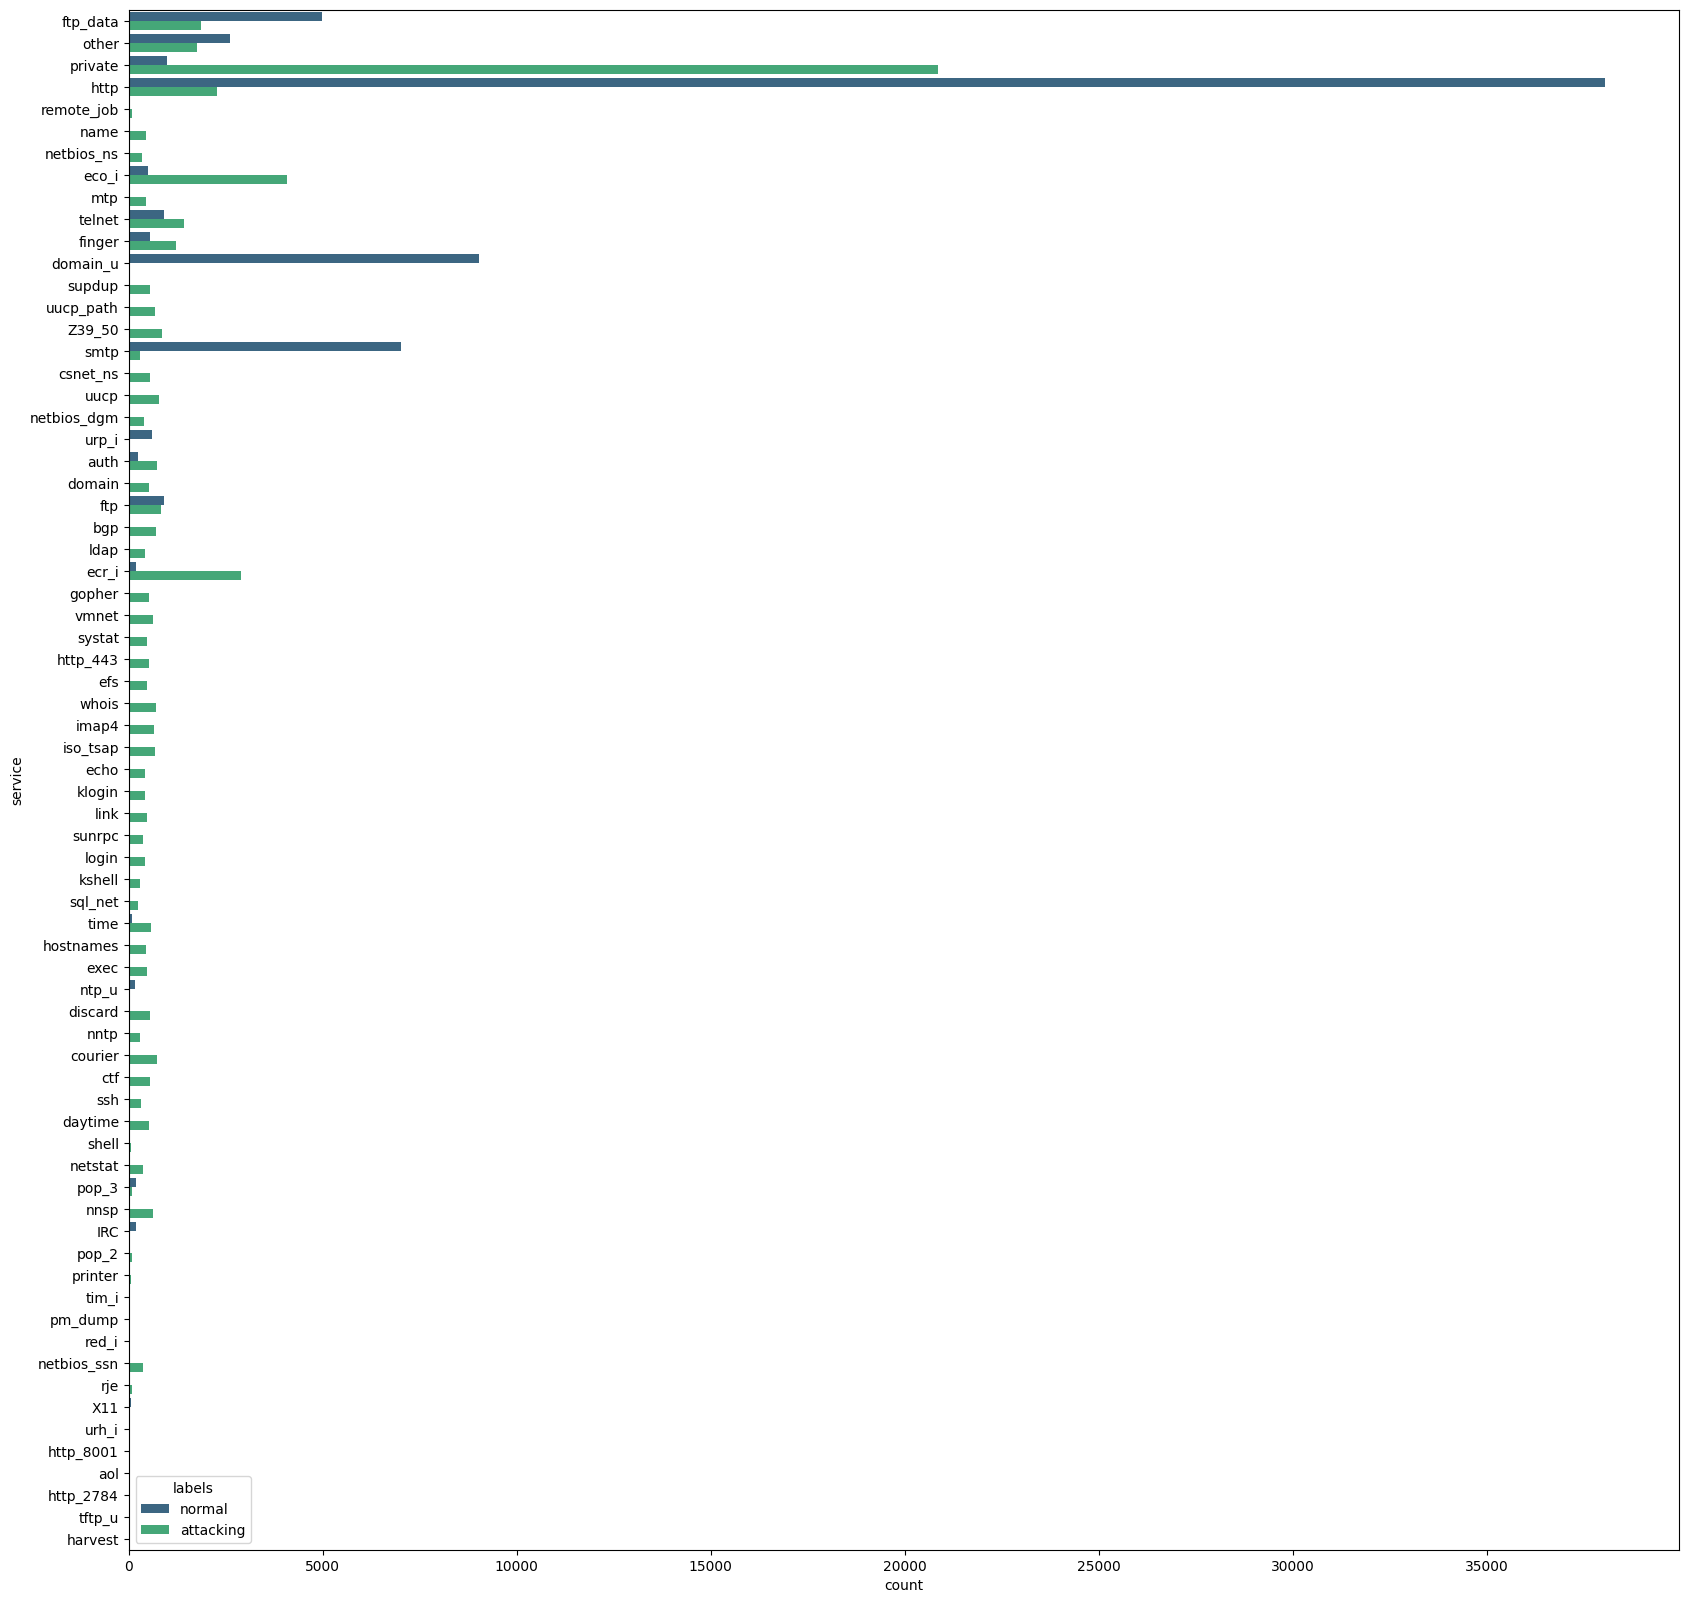

In [ ]:
plt.figure(figsize = (20,20))
sns.countplot(data=trn, y=trn.service, hue = 'labels', palette="viridis")

In [ ]:
c = len(trn.select_dtypes(include=["number"]).columns)
c

38

In [ ]:
cols = ['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment',
       'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised',
       'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
       'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
       'is_guest_login', 'count', 'srv_count', 'serror_rate',
       'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
       'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
       'dst_host_srv_count', 'dst_host_same_srv_rate',
       'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
       'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
       'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
       'dst_host_srv_rerror_rate']

In [ ]:
for col in trn.select_dtypes(include=["object"]):
    print(col)

protocol_type
service
flag
labels


In [ ]:
from sklearn.preprocessing import LabelEncoder

cols = ['protocol_type','service','flag','labels']

for i in cols:
    en = LabelEncoder()

    trn[i] = en.fit_transform(trn[i])

In [ ]:
trn.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,labels
0,0,1,20,9,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,1
1,0,2,44,9,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,1
2,0,1,49,5,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,0
3,0,1,24,9,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,1
4,0,1,24,9,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1


In [ ]:
corr_matrix = trn.corr().abs()
corr_matrix

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,labels
duration,1.000000,0.038241,0.092858,0.063390,0.070737,0.034878,0.001553,0.009866,0.003830,0.000705,...,0.109776,0.116005,0.254195,0.228737,0.026669,0.064948,0.064361,0.173815,0.199024,0.048785
protocol_type,0.038241,1.000000,0.029994,0.093668,0.000974,0.000608,0.001757,0.169535,0.000965,0.011857,...,0.103919,0.001702,0.131380,0.209105,0.356183,0.079398,0.077925,0.015434,0.046938,0.281355
service,0.092858,0.029994,1.000000,0.304014,0.001631,0.003596,0.009952,0.084404,0.010980,0.064066,...,0.407696,0.452696,0.284072,0.111163,0.156211,0.281635,0.277594,0.150666,0.148405,0.276548
flag,0.063390,0.093668,0.304014,1.000000,0.008114,0.004096,0.010373,0.067214,0.005811,0.068437,...,0.582687,0.630118,0.283607,0.195689,0.073773,0.443441,0.443225,0.683310,0.718778,0.647073
src_bytes,0.070737,0.000974,0.001631,0.008114,1.000000,0.000204,0.000109,0.000693,0.000059,0.000295,...,0.006861,0.006572,0.000900,0.000431,0.001655,0.004503,0.003397,0.001468,0.012449,0.005921
dst_bytes,0.034878,0.000608,0.003596,0.004096,0.000204,1.000000,0.000069,0.000440,0.000248,0.000344,...,0.004224,0.004424,0.011031,0.011747,0.001281,0.003024,0.002944,0.011729,0.011223,0.004118
land,0.001553,0.001757,0.009952,0.010373,0.000109,0.000069,1.000000,0.001261,0.000109,0.001340,...,0.014159,0.011597,0.004516,0.033851,0.070474,0.019840,0.012276,0.005222,0.005303,0.007191
wrong_fragment,0.009866,0.169535,0.084404,0.067214,0.000693,0.000440,0.001261,1.000000,0.000692,0.008508,...,0.045240,0.048733,0.059797,0.037177,0.016252,0.051917,0.055917,0.028890,0.033682,0.095905
urgent,0.003830,0.000965,0.010980,0.005811,0.000059,0.000248,0.000109,0.000692,1.000000,0.000293,...,0.007897,0.004489,0.006840,0.002741,0.005176,0.004749,0.004834,0.002999,0.002912,0.002787
hot,0.000705,0.011857,0.064066,0.068437,0.000295,0.000344,0.001340,0.008508,0.000293,1.000000,...,0.051864,0.036293,0.012293,0.034536,0.024715,0.058222,0.058214,0.030555,0.031670,0.013083


In [ ]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))


In [ ]:
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]
to_drop

['num_root',
 'srv_serror_rate',
 'srv_rerror_rate',
 'dst_host_serror_rate',
 'dst_host_srv_serror_rate',
 'dst_host_srv_rerror_rate']

In [ ]:
trn.drop(to_drop, axis=1, inplace=True)

In [ ]:
X_trn = trn.drop(['labels'] , axis = 1).values
Y_trn = trn['labels'].values

In [ ]:
minmax = MinMaxScaler()
X_trn = minmax.fit_transform(X_trn)


In [ ]:
X_trn.shape

(125973, 35)

In [ ]:
x_trn, x_temp, y_trn, y_temp = train_test_split(X_trn, Y_trn, test_size=0.30, random_state=42)

# Second split: Split the remaining 30% into 50% validation and 50% test (15% each)
x_val, x_tst, y_val, y_tst = train_test_split(x_temp, y_temp, test_size=0.50, random_state=42)

In [ ]:
print("Training set shape:", x_trn.shape)
print("Validation set shape:", x_val.shape)
print("Test set shape:", x_tst.shape)

Training set shape: (88181, 35)
Validation set shape: (18896, 35)
Test set shape: (18896, 35)


In [ ]:
TIMESTEPS = 1
x_trn_reshaped = x_trn.reshape((x_trn.shape[0], TIMESTEPS, x_trn.shape[1]))
x_tst_reshaped = x_tst.reshape((x_tst.shape[0], TIMESTEPS, x_tst.shape[1]))
input_shape = (TIMESTEPS, x_trn.shape[1])
epochs = 25
batch_size = 500

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, BatchNormalization, Dropout, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# —————————————————————————————————————————————————————————————
# 1. Hyperparameters from your table
# —————————————————————————————————————————————————————————————
EPOCHS            = 25
BATCH_SIZE        = 500
DROPOUT_RATE      = 0.2
HIDDEN_UNITS      = [600, 800]      # two dense layers: 600 then 800 units
OPTIMIZER         = Adam()          # the “Activation” row in your table was actually the optimizer
FINAL_ACTIVATION  = 'softmax'       # the “Optimization” row in your table was actually the activation
NUM_CLASSES       = y_trn.shape[1]  # assuming one-hot encoded labels

# —————————————————————————————————————————————————————————————
# 2. Build a multiclass DNN
# —————————————————————————————————————————————————————————————
def build_multiclass_dnn(input_shape):
    inp = Input(shape=input_shape)
    x = Flatten()(inp)

    for units in HIDDEN_UNITS:
        x = Dense(units, activation='relu')(x)
        x = BatchNormalization()(x)
        x = Dropout(DROPOUT_RATE)(x)

    out = Dense(NUM_CLASSES, activation=FINAL_ACTIVATION)(x)
    return Model(inputs=inp, outputs=out)

# —————————————————————————————————————————————————————————————
# 3. Prepare data (reshape if needed)
# —————————————————————————————————————————————————————————————
# If your X is already 2D (samples × features) you can skip this.
TIMESTEPS = 1
x_trn_rs = x_trn.reshape((x_trn.shape[0], TIMESTEPS, x_trn.shape[1]))
x_tst_rs = x_tst.reshape((x_tst.shape[0], TIMESTEPS, x_tst.shape[1]))
input_shape = (TIMESTEPS, x_trn.shape[1])

# —————————————————————————————————————————————————————————————
# 4. Instantiate, compile & callbacks
# —————————————————————————————————————————————————————————————
model = build_multiclass_dnn(input_shape)

model.compile(
    optimizer=OPTIMIZER,
    loss='categorical_crossentropy',   # for multiclass
    metrics=['accuracy']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

model_checkpoint = ModelCheckpoint(
    filepath='best_model.keras',
    monitor='val_loss',
    save_best_only=True
)

# —————————————————————————————————————————————————————————————
# 5. Train!
# —————————————————————————————————————————————————————————————
history = model.fit(
    x_trn_rs, y_trn,
    validation_data=(x_tst_rs, y_tst),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping, model_checkpoint]
)


IndexError: tuple index out of range

In [ ]:
from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization, MaxPooling1D, Dropout,
    Dense, Flatten, SimpleRNN, LSTM, Bidirectional
)
from tensorflow.keras.models import Model

def build_cnn(input_shape,
              conv_filters=(64, 128),
              kernel_sizes=(3, 3),
              pool_sizes=(2, 2),
              dropout_rate=0.4):
    """
    Pure 1D CNN model for binary classification.
    """
    inputs = Input(shape=input_shape)
    x = inputs

    # Stacked convolutional blocks
    for filters, ksz, psz in zip(conv_filters, kernel_sizes, pool_sizes):
        x = Conv1D(filters=filters, kernel_size=ksz, padding='same', activation='relu')(x)
        x = BatchNormalization()(x)
        x = MaxPooling1D(pool_size=psz, padding='same')(x)
        x = Dropout(dropout_rate)(x)

    x = Flatten()(x)
    x = Dense(64, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    outputs = Dense(1, activation='sigmoid')(x)
    return Model(inputs, outputs)


def build_dnn(input_shape,
              hidden_units=(128, 64),
              dropout_rate=0.4):
    """
    Deep feed-forward network (DNN) for binary classification.
    Expects input_shape = (timesteps, features) or just (features,).
    If time-series, you may flatten before passing in.
    """
    # if 2D, flatten to vector
    inputs = Input(shape=input_shape)
    x = Flatten()(inputs) if len(input_shape) > 1 else inputs

    # Dense blocks
    for units in hidden_units:
        x = Dense(units, activation='relu')(x)
        x = BatchNormalization()(x)
        x = Dropout(dropout_rate)(x)

    outputs = Dense(1, activation='sigmoid')(x)
    return Model(inputs, outputs)


def build_rnn(input_shape,
              rnn_units=64,
              bidirectional=False,
              dropout_rate=0.4):
    """
    Simple RNN model (optionally bidirectional) for binary classification.
    """
    inputs = Input(shape=input_shape)
    if bidirectional:
        x = Bidirectional(SimpleRNN(rnn_units, return_sequences=False))(inputs)
    else:
        x = SimpleRNN(rnn_units, return_sequences=False)(inputs)
    x = Dropout(dropout_rate)(x)

    x = Dense(64, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    outputs = Dense(1, activation='sigmoid')(x)
    return Model(inputs, outputs)


def build_lstm(input_shape,
               lstm_units=64,
               bidirectional=False,
               dropout_rate=0.4):
    """
    LSTM (optionally bidirectional) model for binary classification.
    """
    inputs = Input(shape=input_shape)
    if bidirectional:
        x = Bidirectional(LSTM(lstm_units, return_sequences=False))(inputs)
    else:
        x = LSTM(lstm_units, return_sequences=False)(inputs)
    x = Dropout(dropout_rate)(x)

    x = Dense(64, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    outputs = Dense(1, activation='sigmoid')(x)
    return Model(inputs, outputs)
